In [1]:
pip install importlib_resources tensorflow_datasets

  Using cached importlib_resources-7.1.0-py3-none-any.whl.metadata (4.0 kB)
  Using cached tensorflow_datasets-4.9.10-py3-none-any.whl.metadata (11 kB)
  Using cached etils-1.15.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached immutabledict-4.3.1-py3-none-any.whl.metadata (3.5 kB)
  Using cached promise-2.3.tar.gz (19 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached simple_parsing-0.1.9-py3-none-any.whl.metadata (8.1 kB)
  Using cached tensorflow_metadata-1.21.0-py3-none-any.whl.metadata (2.5 kB)
  Using cached toml-0.10.2-py2.py3-none-any.whl.metadata (7.1 kB)
  Using cached einops-0.8.2-py3-none-any.whl.metadata (13 kB)
  Using cached docstring_parser-0.18.0-py3-none-any.whl.metadata (3

In [2]:
import tensorflow_datasets as tfds
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

In [3]:
## Loading images and labels
(train_ds, train_labels), (test_ds, test_labels) = tfds.load("tf_flowers",
    split=["train[60%:70%]", "train[70%:80%]"], ## Train test split
    batch_size=-1,
    as_supervised=True,  # Include labels
)

C:\Users\Rudraksha\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 0 url [00:00, ? url/s]
Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]
Generating train examples...: 0 examples [00:00, ? examples/s]
Generating train examples...: 1146 examples [00:01, 1145.32 examples/s]
Generating train examples...: 2857 examples [00:02, 1477.40 examples/s]
                                                                       
Shuffling C:\Users\Rudraksha\tensorflow_datasets\tf_flowers\incomplete.TPWUDM_3.0.1\tf_flowers-train.tfrecord-[0-9][0-9][0-9][0-9][0-9]-of-[0-9][0-9][0-9][0-9][0-9]...:   0%|          | 0/3670 [00:00<?, ? examples/s]
                                                                                                                     

Dataset tf_flowers downloaded and prepared to C:\Users\Rudraksha\tensorflow_datasets\tf_flowers\3.0.1. Subsequent calls will reuse this data.



In [4]:
## check existing image size
train_ds[0].shape

TensorShape([412, 1024, 3])

In [5]:
## Resizing images
train_ds = tf.image.resize(train_ds, (150, 150))
test_ds = tf.image.resize(test_ds, (150, 150))

In [6]:
train_labels

<tf.Tensor: shape=(367,), dtype=int64, numpy=
array([3, 0, 4, 4, 0, 4, 3, 1, 0, 3, 2, 2, 0, 4, 4, 1, 4, 2, 0, 0, 2, 0,
       2, 1, 0, 0, 1, 2, 0, 1, 3, 3, 1, 2, 4, 4, 1, 0, 4, 4, 0, 2, 1, 2,
       3, 1, 4, 4, 2, 4, 3, 3, 0, 3, 2, 3, 3, 2, 3, 0, 4, 3, 4, 2, 3, 1,
       3, 2, 2, 1, 3, 0, 4, 3, 2, 1, 3, 0, 3, 4, 0, 0, 0, 2, 3, 2, 0, 3,
       1, 0, 4, 1, 2, 3, 0, 0, 4, 2, 2, 4, 1, 2, 2, 0, 0, 0, 4, 3, 3, 3,
       1, 2, 4, 1, 0, 3, 1, 0, 0, 3, 0, 2, 0, 4, 2, 0, 2, 3, 3, 3, 2, 0,
       3, 0, 0, 4, 4, 1, 4, 0, 4, 0, 1, 3, 2, 0, 2, 1, 2, 0, 2, 4, 3, 4,
       4, 4, 4, 0, 4, 4, 2, 1, 3, 0, 2, 1, 3, 2, 4, 0, 1, 2, 4, 0, 2, 4,
       3, 0, 4, 2, 0, 3, 2, 0, 0, 2, 3, 1, 4, 0, 0, 3, 0, 4, 1, 4, 4, 3,
       3, 1, 0, 3, 4, 0, 1, 3, 3, 0, 4, 4, 3, 1, 1, 2, 2, 0, 2, 3, 1, 4,
       3, 3, 2, 2, 0, 0, 0, 3, 3, 2, 2, 1, 0, 3, 1, 2, 2, 2, 4, 4, 2, 2,
       1, 3, 3, 3, 1, 0, 2, 1, 3, 2, 0, 3, 2, 3, 0, 0, 1, 1, 2, 0, 0, 4,
       2, 2, 4, 3, 2, 0, 1, 1, 4, 2, 3, 1, 0, 4, 1, 1, 4, 4, 0, 4, 0, 3,
     

In [7]:
## Transforming labels to correct format
train_labels = to_categorical(train_labels, num_classes=5)
test_labels = to_categorical(test_labels, num_classes=5)

In [8]:
train_labels[0]

<tf.Tensor: shape=(5,), dtype=float32, numpy=array([0., 0., 0., 1., 0.], dtype=float32)>

In [9]:
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [10]:
train_ds[0].shape

TensorShape([150, 150, 3])

In [11]:
## Loading VGG16 model
base_model = VGG16(weights="imagenet", include_top=False, input_shape=train_ds[0].shape)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [12]:
## will not train base mode
# Freeze Parameters in model's lower convolutional layers
base_model.trainable = False

In [13]:
## Preprocessing input
train_ds = preprocess_input(train_ds)
test_ds = preprocess_input(test_ds)

In [14]:
## model details
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 150, 150, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 150, 150, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 75, 75, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 75, 75, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 75, 75, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 37, 37, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 37, 37, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 37, 37, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 37, 37, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 18, 18, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 18, 18, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 18, 18, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 18, 18, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 9, 9, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 4, 4, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [15]:
#add our layers on top of this model
from tensorflow.keras import layers, models

flatten_layer = layers.Flatten()
dense_layer_1 = layers.Dense(50, activation='relu')
dense_layer_2 = layers.Dense(20, activation='relu')
prediction_layer = layers.Dense(5, activation='softmax')


model = models.Sequential([
    base_model,
    flatten_layer,
    dense_layer_1,
    dense_layer_2,
    prediction_layer
])

In [16]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

In [17]:
es = EarlyStopping(monitor='val_accuracy', mode='max', patience=5,  restore_best_weights=True)

In [18]:
history=model.fit(train_ds, train_labels, epochs=5, validation_split=0.2, batch_size=32, callbacks=[es])

Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.2969 - loss: 4.2380 - val_accuracy: 0.5135 - val_loss: 2.9222
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.7509 - loss: 0.8985 - val_accuracy: 0.5135 - val_loss: 2.3715
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8669 - loss: 0.3449 - val_accuracy: 0.5541 - val_loss: 2.4771
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9556 - loss: 0.1404 - val_accuracy: 0.4865 - val_loss: 2.6096
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9761 - loss: 0.0974 - val_accuracy: 0.5676 - val_loss: 2.4998


In [19]:
los,accurac=model.evaluate(test_ds,test_labels)
print("Loss: ",los,"Accuracy: ", accurac)

12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 939ms/step - accuracy: 0.5559 - loss: 2.8491
Loss:  2.849079132080078 Accuracy:  0.555858314037323


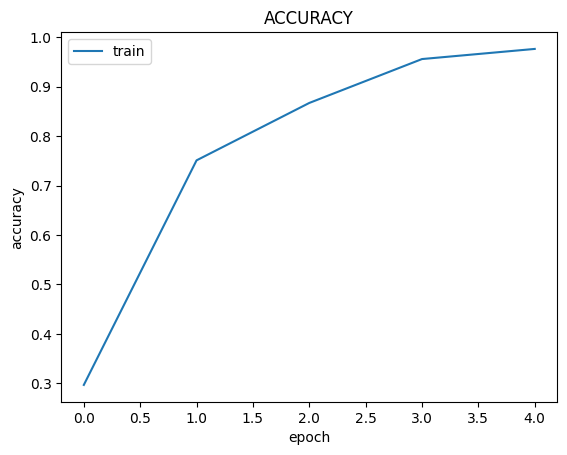

In [20]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.title('ACCURACY')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train'],loc='upper left')
plt.show()

In [21]:
import numpy as np
import pandas as pd
y_pred = model.predict(test_ds)
y_classes = [np.argmax(element) for element in y_pred]
#to_categorical(y_classes, num_classes=5)
#to_categorical(test_labels, num_classes=5)
print(y_classes[:10])
print("\nTest")
print(test_labels[:10])

12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 960ms/step
[np.int64(4), np.int64(2), np.int64(1), np.int64(3), np.int64(2), np.int64(1), np.int64(2), np.int64(3), np.int64(0), np.int64(2)]

Test
tf.Tensor(
[[0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0.]], shape=(10, 5), dtype=float32)
